In [1]:
import glob
from ISRpy import beampack

jro0 = beampack.jrobeam

# from IPython import display
import random
import numpy as np
import datetime
import scipy.constants as const


In [2]:
from OXmodeCython import OXmode_cython

In [3]:
training_dir = 'training_data'

d = np.load('JM91J_2016014141141.npy', allow_pickle=True)[()]
freqs = d['vipir_freqs']
hts = d['vipir_hts']

noise_dir = 'VIPIR_PROC/Dog_noise/'
noise_files = glob.glob1(noise_dir,'*.npy')
print(len(noise_files))

139


In [4]:
ipp = 5.6e3*0.15
print(ipp)
ipp - hts[-1]*1

840.0


np.float64(66.44999999999959)

In [5]:
from forward_gentrain import GenTrain
gt = GenTrain(freqs,hts,ipp,training_dir,noise_dir)


In [6]:
dt0 = datetime.datetime(2015,4,15)
igrf_year = dt0.year + (dt0-datetime.datetime(dt0.year,1,1)).total_seconds() / (
        datetime.datetime(dt0.year+1,1,1)-datetime.datetime(dt0.year,1,1)).total_seconds()

dz=0.5 # resolution in km --- 0.1 is for good resolution, 0.5 for speed
zmax = 800
Z = np.arange(0.01,zmax,dz)

fes = []
for iZ in Z:
    r,geoc_lat,lon,aspect,B = jro0.aspect_angle(igrf_year,jro0.xyz0 + jro0.zenith0 * iZ)
    fes += [const.e * np.linalg.norm(B) * 1e-9 / const.m_e /1e6 /2/np.pi] #MHz
fes = np.array(fes)


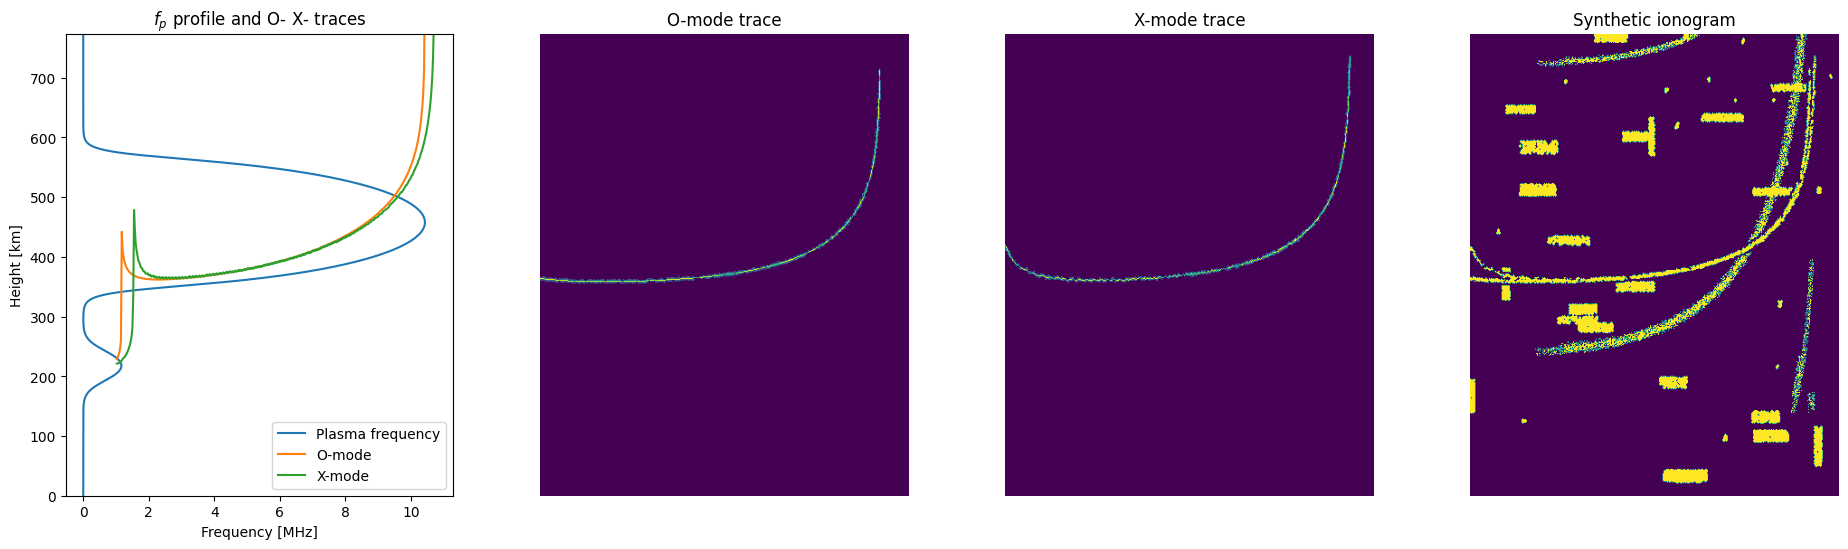

In [ ]:
gt.graph_generate(fes, Z, dz, savedata = False)

In [8]:
from joblib import Parallel, delayed
import multiprocessing as mp
# from multiprocessing import Pool

# Generate parameters for the images [0.9,400,40,0.5,300,40,0.1,150,40]
para_func = lambda x : gt.graph_generate(fes, Z, dz, savedata = True)
# Use all available CPU cores to generate the graphs in parallel

Parallel(n_jobs=mp.cpu_count()-0)(delayed(para_func)(_) for _ in range(9000))



[None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,